<a href="https://colab.research.google.com/github/daryamraeva/BigData_MGPU/blob/main/%D0%A1%D0%A6%D0%A2%20%D0%9B%D0%911.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа № 1
## Виртуальный цифровой двойник мобильного робота

**Дисциплина:** «Цифровые технологии»

**Раздел:** Мобильная робототехника

**Среда:** Google Colab / Jupyter · Python 3 · NumPy, Pandas, Matplotlib

**Максимум:** 20 баллов

---

### Цель работы

Разработать виртуальный цифровой двойник двухколёсного мобильного робота и исследовать его
движение, управление и реакцию на препятствия.

### Что используется готовым, а что вы пишете сами

| Готовое (из `robotics-course`) | Ваша реализация |
|---|---|
| кинематическая модель `DiffDrive` | виртуальный дальномер |
| регулятор `PIDController` | конечный автомат `IDLE → RUN → AVOID → GOAL/FAULT` |
| генерация карты препятствий | законы управления в состояниях |
| код построения графиков | цикл моделирования и расчёт метрик |

### Критерии оценки — 20 баллов

| Часть | Содержание | Баллы |
|---|---|---|
| 1 | Сцена и виртуальный дальномер | 5 |
| 2 | Конечный автомат и законы управления | 5 |
| 3 | Цикл моделирования и достижение цели | 4 |
| 4 | Три графика и таблица метрик | 4 |
| 5 | Исследование влияния порога AVOID и вывод | 2 |

### Материалы

* Каталог мобильных роботов —
  <https://github.com/BosenkoTM/robotics-course/tree/2026/04-mobile-robots>
* Основной notebook `class.ipynb` —
  <https://github.com/BosenkoTM/robotics-course/blob/2026/04-mobile-robots/class.ipynb>
* Кинематические модели —
  <https://github.com/BosenkoTM/robotics-course/blob/2026/04-mobile-robots/lib/kinematic_models.py>
* Регуляторы —
  <https://github.com/BosenkoTM/robotics-course/blob/2026/04-mobile-robots/lib/controllers.py>
* Уровни управления —
  <https://github.com/BosenkoTM/robotics-course/blob/2026/03-control/class.ipynb>

> ### ВАРИАНТ ПРЕПОДАВАТЕЛЯ
> Полное решение всех заданий, ноутбук выполнен целиком. Эталонный прогон сделан по варианту 1.
> Решение проверено на всех 25 вариантах: во всех случаях робот достигает цели (состояние GOAL) без столкновений.
> Студенческий вариант отличается только содержимым кодовых ячеек.


---

# Теоретическое введение


## 1. Что такое цифровой двойник

**Цифровой двойник (digital twin)** — исполняемая модель физического объекта, связанная с ним
данными и используемая для анализа, прогноза и управления. Принято различать три уровня
зрелости:

| Уровень | Связь с объектом | Что даёт |
|---|---|---|
| **Цифровая модель** (digital model) | связи нет, данные переносятся вручную | расчёт «что было бы, если» |
| **Цифровая тень** (digital shadow) | односторонняя: объект → модель | мониторинг, диагностика по телеметрии |
| **Цифровой двойник** (digital twin) | двусторонняя: объект ↔ модель | модель влияет на управление объектом |

В этой работе строится **виртуальный двойник**: физического робота нет, его роль играет
кинематическая модель. Это стандартный первый шаг — так проверяют логику управления до
выхода на железо, где ошибка стоит поломанного робота. Всё, что мы напишем (дальномер,
автомат, законы управления, журнал телеметрии), в реальном проекте переносится на робота
без изменения структуры: меняется только источник данных — вместо `ray_distance` приходят
показания настоящего лидара.

Три обязательных элемента двойника, которые мы реализуем:

1. **Модель динамики** — как состояние меняется во времени (`DiffDrive`);
2. **Модель восприятия** — что объект «видит» (виртуальный дальномер);
3. **Телеметрия** — журнал состояний и решений, пригодный для анализа (`telemetry.csv`).

## 2. Кинематика дифференциального привода

Робот с двумя независимо управляемыми колёсами описывается позой
$\mathbf{q} = [x, y, \theta]^{\mathsf{T}}$ и управлением $(v, \omega)$ — линейная и угловая
скорости. Уравнения движения:

$$\dot{x} = v\cos\theta, \qquad \dot{y} = v\sin\theta, \qquad \dot{\theta} = \omega$$

Скорости колёс связаны с $(v,\omega)$ через радиус колеса $r$ и колею $L$:

$$v = \frac{r(\omega_R + \omega_L)}{2}, \qquad \omega = \frac{r(\omega_R - \omega_L)}{L}$$

В работе используется `DiffDrive(wheel_radius=0.05, wheel_base=0.20)` — колесо 5 см, колея
20 см. Метод `robot.forward(pose, v, omega, DT)` выполняет **численное интегрирование**
(шаг Эйлера): новая поза получается сдвигом на $v\,\Delta t$ вдоль текущего курса и
доворотом на $\omega\,\Delta t$.

Два следствия, важных для понимания результатов:

* **Неголономность.** Робот не может сместиться вбок: любое перемещение происходит вдоль
  собственной оси. Поэтому объезд препятствия — всегда дуга, а не сдвиг, и траектория
  получается длиннее прямой.
* **Ошибка дискретизации.** При шаге $\Delta t = 0{,}05$ с (20 Гц) и скорости 0,55 м/с робот
  за шаг проходит около 2,7 см. Уменьшение шага повышает точность и линейно увеличивает
  время счёта; увеличение — экономит время, но модель начинает «срезать» дуги.

## 3. Восприятие: виртуальный дальномер

Реальный лидар измеряет расстояние до ближайшей поверхности вдоль луча. В симуляции то же
самое считается аналитически — метод **трассировки луча (ray casting)**.

Луч из точки $\mathbf{O}$ в направлении единичного вектора $\mathbf{d}$:
$\mathbf{P}(t) = \mathbf{O} + t\,\mathbf{d}$, $t \ge 0$. Подставив в уравнение окружности
радиуса $R$ с центром $\mathbf{C}$, получаем квадратное уравнение относительно $t$
(коэффициент при $t^2$ равен единице именно потому, что $\mathbf{d}$ единичный):

$$t^2 + bt + c = 0, \qquad b = 2(\mathbf{f}\cdot\mathbf{d}), \quad
c = \mathbf{f}\cdot\mathbf{f} - R^2, \quad \mathbf{f} = \mathbf{O} - \mathbf{C}$$

Дискриминант $D = b^2 - 4c$: при $D < 0$ луч проходит мимо, иначе берётся наименьший
**неотрицательный** корень — отрицательные соответствуют пересечениям «позади» робота.

### Конфигурационное пространство

Учитывать форму робота в каждом расчёте дорого. Стандартный приём — **сумма Минковского**:
робот считается точкой, а все препятствия «раздуваются» на радиус робота плюс запас
безопасности. Здесь $R_{\text{эфф}} = r_{\text{препятствия}} + R_{\text{робота}} + \text{SAFETY}
= r + 0{,}15 + 0{,}10$ м. На графиках раздутые препятствия показаны красным пунктиром.

Именно поэтому в работе два разных понятия расстояния, и их нельзя путать:

| Функция | Что измеряет | Где используется |
|---|---|---|
| `ray_distance` / `scan` | расстояние по лучу до **раздутого** препятствия | восприятие, вход автомата и законов управления |
| `clearance` | реальный зазор до **поверхности** препятствия | контроль столкновения и метрика безопасности |

## 4. Управление

### 4.1. ПИД-регулятор

Классический закон: управляющее воздействие пропорционально ошибке, её интегралу и
производной:

$$u(t) = K_p e(t) + K_i\!\int_0^t\! e(\tau)\,d\tau + K_d \frac{de(t)}{dt}$$

В `PIDController` два независимых контура — по расстоянию до цели (даёт $v$) и по угловому
рассогласованию (даёт $\omega$), оба с насыщением `max_v` и `max_omega`. Интегральные
коэффициенты в работе обнулены (`ki_lin=0, ki_ang=0`): при отсутствии постоянного
возмущения интегратор только накапливает ошибку за время обхода препятствия и даёт рывок
при возврате к цели. Это явление называется **интегральным насыщением (windup)**; в коде
цикла оно дополнительно снимается вызовом `pid.reset()` при каждом входе в состояние `RUN`.

### 4.2. Три архитектуры управления

| Архитектура | Принцип | Достоинство | Недостаток |
|---|---|---|---|
| **Делиберативная** (sense-plan-act) | построить карту, спланировать маршрут, исполнить | оптимальность, гарантия достижимости | нужна карта, медленно реагирует на изменения |
| **Реактивная** (sense-act) | прямое отображение «показания датчиков → управление» | быстро, не требует карты | застревание в локальных минимумах, неоптимальный путь |
| **Гибридная** | глобальный планировщик + локальный реактивный слой | компромисс | сложность согласования слоёв |

Наш робот — **чисто реактивный**. Он не знает карты: список `obstacles` доступен только
симулятору сцены, а робот получает лишь девять чисел от дальномера. Отсюда и главный
результат работы: путь длиннее прямой, а поведение принципиально не гарантирует
оптимальности. Историческая основа подхода — субсумпционная архитектура Р. Брукса (1986):
интеллектуальное поведение как надстройка простых реакций друг над другом.

### 4.3. Конечный автомат и поведения

**Конечный автомат (FSM)** — пятёрка «состояния, входные сигналы, функция переходов,
начальное состояние, терминальные состояния». Здесь состояния — это **поведения**:

* `IDLE` — стоим (начальное);
* `RUN` — движение к цели по ПИД;
* `AVOID` — обход методом свободного сектора;
* `GOAL`, `FAULT` — терминальные: цель достигнута / столкновение.

**Гистерезис и выдержка.** Если порог входа в `AVOID` и порог выхода из него совпадают, то
вблизи порога состояние переключается на каждом шаге — автомат «дребезжит». Приём тот же,
что в термостате и в антидребезге кнопки: выход разрешён при пороге, увеличенном в
`HYST = 1.6` раза, и не раньше чем через `DWELL = 0.30` с после входа.

## 5. Метрики и методика эксперимента

Оценивать поведение «на глаз» по картинке нельзя — нужны числа. В работе считаются:

| Метрика | Смысл | Как читать |
|---|---|---|
| `final_state` | чем закончился эксперимент | `GOAL` — успех, `FAULT` — столкновение |
| `time_s` | модельное время | сравнимо только при одинаковой карте |
| `path_length_m` | длина пройденного пути | сумма длин отрезков траектории |
| `straight_line_m` | прямое расстояние старт → цель | нижняя граница длины пути |
| `tortuosity` | **извилистость** = путь / прямая | 1,0 — идеально прямо; 1,3 — перепробег 30 % |
| `fsm_transitions` | число переключений автомата | косвенная мера «дёрганости» поведения |
| `avoid_share` | доля времени в `AVOID` | сколько робот занимался обходом, а не движением к цели |
| `min_clearance_m` | минимальный зазор за эксперимент | мера безопасности; сравнивается с `ROBOT_R` |
| `mean_speed_ms` | средняя скорость | показывает, сколько «съел» режим обхода |

**Однофакторный эксперимент.** В части 5 меняется ровно один параметр — порог `AVOID`, —
а карта, старт, цель и все прочие настройки фиксированы. Только так наблюдаемое изменение
метрик можно приписать именно этому параметру. Воспроизводимость обеспечена детерминированным
генератором карты: `np.random.default_rng(cfg["seed"])` при одном и том же `seed` всегда
даёт одну и ту же сцену.

## 6. Ограничения модели — что сознательно упрощено

Понимание границ модели важнее, чем сам код. В нашем двойнике отсутствуют:

1. **Динамика.** Управление $(v, \omega)$ исполняется мгновенно и точно: нет масс, инерции,
   пробуксовки, ограничений на ускорение. У реального робота смена скорости занимает время.
2. **Шум датчика.** Показания дальномера идеальны. Настоящий лидар даёт разброс, промахи
   на зеркальных и тёмных поверхностях, ложные отражения.
3. **Погрешность одометрии.** Поза известна точно. На реальном роботе она накапливает
   ошибку, и её приходится оценивать (фильтр Калмана, SLAM).
4. **Динамические препятствия.** Все круги неподвижны; людей и других роботов нет.
5. **Локальные минимумы.** Реактивная схема может застрять в вогнутом препятствии
   (U-образная ловушка). На нашей карте препятствия выпуклые и расставлены свободно,
   поэтому ловушек не возникает — но это свойство сцены, а не алгоритма.

Разрыв между поведением в симуляции и на реальном роботе называется **sim-to-real gap**;
он же — тема задачи повышенной сложности в конце ноутбука.

## 7. Обозначения

| Обозначение | Смысл | Значение в работе |
|---|---|---|
| `MAP_SIZE` | сторона квадратной площадки | 10 м |
| `START`, `GOAL` | стартовая поза $[x,y,\theta]$ и цель $[x,y]$ | `[0.5, 0.5, 0]`, `[9, 9]` |
| `ROBOT_R` | радиус корпуса | 0,15 м |
| `SAFETY` | запас безопасности | 0,10 м |
| `DT` | шаг моделирования | 0,05 с (20 Гц) |
| `MAX_TIME` | предел длительности эксперимента | 90 с |
| `GOAL_TOL` | радиус зоны цели | 0,25 м |
| `BEAMS` | углы лучей дальномера | 9 лучей в секторе ±90° |
| `FRONT` | центральный сектор | лучи −15°, 0°, +15° |
| `HYST`, `DWELL` | гистерезис и выдержка автомата | 1,6 и 0,30 с |

---

---
## Задание 0. Вариант и среда

**Разбор ячейки.** Параметры варианта вычисляются формулой, а не берутся из таблицы —
это гарантирует, что у 25 студентов не совпадут одновременно все четыре настройки.
Схема разбиения: `(n-1) % 5` даёт остаток 0…4 и управляет **скоростью** и **порогом**,
`(n-1) // 5` даёт 0…4 и управляет **дальностью датчика** и **числом препятствий**. Получается
матрица 5×5: каждая пара «скорость — дальность» встречается ровно один раз. Поле `seed`
делает карту варианта воспроизводимой: при повторном запуске сцена будет та же.

In [1]:
# =========== ЭТАЛОННЫЙ ПРОГОН ===========
STUDENT_NAME  = "МРАЕВА ДАРЬЯ"
STUDENT_GROUP = "ИНДОР-221"
VARIANT       = 8
# ========================================

assert 1 <= VARIANT <= 25, "Вариант — целое число от 1 до 25"


def variant_params(n: int) -> dict:
    """Параметры варианта по таблице задания."""
    return {
        "speed":            round(0.55 + 0.03 * ((n - 1) % 5), 2),   # м/с
        "sensor_range":     round(1.6 + 0.2 * ((n - 1) // 5), 1),    # м
        "avoid_threshold":  round(0.55 + 0.05 * ((n - 1) % 5), 2),   # м
        "obstacles_count":  3 + ((n - 1) // 5),
        "seed":             100 + n,
    }


cfg = variant_params(VARIANT)
print(f"Студент : {STUDENT_NAME}, группа {STUDENT_GROUP}")
print(f"Вариант : {VARIANT}")
for k, v in cfg.items():
    print(f"  {k:<18}: {v}")

Студент : МРАЕВА ДАРЬЯ, группа ИНДОР-221
Вариант : 8
  speed             : 0.61
  sensor_range      : 1.8
  avoid_threshold   : 0.65
  obstacles_count   : 4
  seed              : 108


**Что получено.** Для варианта 1: скорость 0,55 м/с, дальность датчика 1,6 м, порог
`AVOID` 0,55 м, три препятствия, `seed = 101`. Это «лёгкий» угол матрицы вариантов —
медленный робот, близорукий датчик, редкая обстановка.

**Преподавателю.** Первое, что проверяется в студенческой работе, — совпадает ли `VARIANT`
с номером в списке группы и не осталось ли в `STUDENT_NAME` значение по умолчанию (это
контролирует и самопроверка в конце). Параметры варианта не должны правиться руками:
подгонка `avoid_threshold` под удобный результат — типичная попытка обойти часть 5.

### Подключение репозитория `robotics-course`

Клонируем ветку `2026` и добавляем каталог `04-mobile-robots` в путь поиска модулей.
Из библиотеки берём только два класса: `DiffDrive` и `PIDController`.

**Разбор ячейки.** Клонирование выполняется с флагом `--depth 1` — скачивается только
последний коммит ветки `2026`, без истории; это экономит время в Colab. Каталог
`04-mobile-robots` добавляется в `sys.path`, после чего библиотека доступна как обычный
модуль. Конструкция `try / except` нужна потому, что пакет `lib` при импорте целиком тянет
зависимости, которых в Colab может не быть; в этом случае нужные модули берутся напрямую —
`kinematic_models` и `controllers`.

In [2]:
from pathlib import Path
import subprocess
import sys

repo = Path("robotics-course")
if not repo.exists():
    subprocess.run(
        ["git", "clone", "--depth", "1", "--branch", "2026",
         "https://github.com/BosenkoTM/robotics-course.git", str(repo)],
        check=True,
    )

mobile = (repo / "04-mobile-robots").resolve()
sys.path.insert(0, str(mobile))

try:
    from lib import DiffDrive, PIDController
except Exception:                      # пакет тянет много зависимостей — берём модули напрямую
    sys.path.insert(0, str(mobile / "lib"))
    from kinematic_models import DiffDrive
    from controllers import PIDController

print("DiffDrive     :", DiffDrive)
print("PIDController :", PIDController)

DiffDrive     : <class 'lib.kinematic_models.DiffDrive'>
PIDController : <class 'lib.controllers.PIDController'>


**Что получено.** Импортированы два класса: `DiffDrive` (кинематика) и `PIDController`
(регулятор). Всё остальное в работе пишется самостоятельно.

**Если ячейка не отработала.** Типичная причина — отсутствие сети в среде выполнения.
Проверьте, что `git` доступен, а репозиторий клонировался: каталог `robotics-course` должен
появиться рядом с ноутбуком. Повторный запуск ячейки безопасен: клонирование выполняется
только при отсутствии каталога.

In [3]:
import json
import math
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

matplotlib.rcParams["figure.dpi"] = 110
matplotlib.rcParams["font.size"] = 9

# --- параметры сцены (одинаковы для всех вариантов)
MAP_SIZE = 10.0                 # размер квадратной площадки, м
START    = np.array([0.5, 0.5, 0.0])   # стартовая поза [x, y, theta]
GOAL     = np.array([9.0, 9.0])        # координаты цели
ROBOT_R  = 0.15                 # радиус корпуса робота, м
SAFETY   = 0.10                 # запас безопасности, м
DT       = 0.05                 # шаг моделирования, с
MAX_TIME = 90.0                 # предельная длительность эксперимента, с
GOAL_TOL = 0.25                 # радиус зоны цели, м

# Веер лучей дальномера: 9 лучей в секторе +-90 градусов
BEAMS = np.deg2rad([-90.0, -60.0, -35.0, -15.0, 0.0, 15.0, 35.0, 60.0, 90.0])
FRONT = slice(3, 6)             # центральный сектор -15..+15 градусов

print(f"Сцена {MAP_SIZE}x{MAP_SIZE} м, старт {START[:2]}, цель {GOAL}, шаг {DT} с")
print(f"Лучей дальномера: {len(BEAMS)}, дальность {cfg['sensor_range']} м")

Сцена 10.0x10.0 м, старт [0.5 0.5], цель [9. 9.], шаг 0.05 с
Лучей дальномера: 9, дальность 1.8 м


**Что получено.** Заданы константы сцены, единые для всех вариантов, — благодаря этому
работы студентов сопоставимы между собой.

**На что обратить внимание:**

* `DT = 0.05` с — это 20 Гц, типичная частота контура управления мобильного робота. При
  скорости 0,55 м/с за один шаг робот проходит около 2,7 см, то есть препятствие радиусом
  0,5 м не может быть «перепрыгнуто» между шагами.
* `BEAMS` — девять лучей в секторе ±90°, неравномерно: впереди они гуще (−15°, 0°, +15°),
  по краям реже. Так же устроены и реальные датчики: разрешение важнее там, куда робот едет.
* `FRONT = slice(3, 6)` вырезает из списка показаний ровно эти три центральных луча.
  `min(d[FRONT])` — «что ближе всего прямо по курсу» — главный входной сигнал автомата.
* `GOAL_TOL = 0.25` м — цель считается достигнутой при попадании в круг этого радиуса.
  Требовать точного совпадения с точкой нельзя: при дискретном шаге робот её просто
  перескочит.

---
# Часть 1. Сцена и виртуальный дальномер (5 баллов)

## 1.1. Карта препятствий

Ячейка готова. Препятствия — круги случайного радиуса; генератор детерминирован по `seed`
варианта, поэтому карта воспроизводима. Гарантируется, что препятствия не перекрывают старт
и цель и оставляют между собой проходы.

**Разбор ячейки.** Карта строится в три приёма.

1. **Блокирующее препятствие.** Первый круг ставится на отрезке «старт — цель» в случайной
   точке между 35 % и 65 % пути, со случайным боковым смещением. Вектор `nvec` —
   перпендикуляр к направлению на цель, полученный поворотом на 90°: из `(dx, dy)`
   получается `(−dy, dx)`. Без этого приёма на редкой карте робот мог бы доехать до цели по
   прямой, ни разу не войдя в `AVOID`, и половина работы осталась бы непроверенной.
2. **Остальные препятствия** размещаются **методом отклонения** (rejection sampling):
   генерируем случайную точку и отбрасываем её, если круг накрывает старт, цель или
   оказывается ближе `sep` к уже поставленному препятствию.
3. **Адаптивное ослабление.** Если за 4000 попыток нужное число кругов разместить не
   удалось, требование к зазору `sep` уменьшается на 0,15 м и попытка повторяется. Так
   гарантируется, что генератор завершится и для 7 препятствий на площадке 10×10 м.

In [4]:
def make_obstacles(cfg: dict) -> list[tuple[float, float, float]]:
    """Список препятствий (x, y, r). Детерминирован по cfg['seed']."""
    rng = np.random.default_rng(cfg["seed"])
    # первое препятствие ставим на прямой «старт — цель», чтобы обход был неизбежен
    d = GOAL - START[:2]
    tt = rng.uniform(0.35, 0.65)
    nvec = np.array([-d[1], d[0]]) / np.linalg.norm(d)
    base = START[:2] + tt * d + nvec * rng.uniform(-0.35, 0.35)
    blocker = (float(base[0]), float(base[1]), float(rng.uniform(0.55, 0.75)))

    sep = 1.4                                     # минимальный зазор между препятствиями
    while sep > 0.5:
        obs, attempts = [blocker], 0
        while len(obs) < cfg["obstacles_count"] and attempts < 4000:
            attempts += 1
            x, y = rng.uniform(1.8, MAP_SIZE - 1.8, size=2)
            r = rng.uniform(0.40, 0.70)
            if np.hypot(x - START[0], y - START[1]) < r + 1.2:
                continue
            if np.hypot(x - GOAL[0], y - GOAL[1]) < r + 1.2:
                continue
            if any(np.hypot(x - o[0], y - o[1]) < r + o[2] + sep for o in obs):
                continue
            obs.append((float(x), float(y), float(r)))
        if len(obs) == cfg["obstacles_count"]:
            return obs
        sep -= 0.15                               # не удалось разместить — ослабляем требование
    return obs


obstacles = make_obstacles(cfg)
print(f"Препятствий: {len(obstacles)}")
for i, (x, y, r) in enumerate(obstacles, 1):
    print(f"  {i}: центр ({x:.2f}, {y:.2f}), радиус {r:.2f} м")

assert len(obstacles) == cfg["obstacles_count"]

Препятствий: 4
  1: центр (5.59, 5.72), радиус 0.57 м
  2: центр (4.04, 3.34), радиус 0.42 м
  3: центр (7.77, 7.79), радиус 0.51 м
  4: центр (2.22, 5.26), радиус 0.53 м


**Что получено.** Три препятствия варианта 1 с координатами и радиусами. Между ними
остаются проходы шириной не менее `sep`, поэтому задача заведомо разрешима — это важное
свойство: студент не должен получить нерешаемую сцену.

**Преподавателю.** Ячейка «готовая», её студент не пишет. Но именно она объясняет, почему у
каждого варианта своя картинка и почему сравнивать абсолютные длины путей между вариантами
некорректно — сравнивать нужно извилистость (`tortuosity`), она нормирована на прямое
расстояние.

## Упражнение 1.2. Зазор до ближайшего препятствия

Реализуйте `clearance(pose, obstacles)` — расстояние от центра робота до **поверхности**
ближайшего препятствия. Если препятствий нет, верните большое число.

```text
clearance = min по препятствиям ( расстояние до центра − радиус )
```

Робот считается столкнувшимся, когда `clearance < ROBOT_R`.

In [5]:
def clearance(pose: np.ndarray, obstacles: list) -> float:
    """Расстояние от центра робота до поверхности ближайшего препятствия, м."""
    if not obstacles:
        return 99.0
    return min(float(np.hypot(pose[0] - x, pose[1] - y) - r) for x, y, r in obstacles)


_p = np.array([0.5, 0.5, 0.0])
print(f"Зазор в стартовой точке: {clearance(_p, obstacles):.3f} м")

assert clearance(_p, []) > 50, "Без препятствий зазор должен быть большим"
_test = [(1.0, 0.5, 0.2)]
assert abs(clearance(_p, _test) - 0.3) < 1e-9, "0.5 м до центра минус радиус 0.2 = 0.3"
assert clearance(_p, obstacles) > ROBOT_R, "Старт не должен находиться внутри препятствия"

Зазор в стартовой точке: 4.117 м


**Что получено.** Зазор в стартовой точке заведомо больше радиуса робота — старт свободен.
Три проверки закрывают три случая: пустой список препятствий, ручной расчёт (0,5 м до центра
минус радиус 0,2 м = 0,3 м) и отсутствие столкновения на старте.

**Ключевое различие, которое чаще всего путают студенты.** `clearance` работает с
**настоящими** радиусами препятствий, без раздутия. Это «объективная» геометрия сцены,
доступная симулятору, но не роботу: она используется только для фиксации столкновения
(`clr < ROBOT_R`) и как метрика безопасности. Робот же «видит» мир через `ray_distance`, где
препятствия раздуты на `ROBOT_R + SAFETY`. Если перепутать эти две функции, робот либо
начнёт считать столкновением нормальный проезд, либо, наоборот, протаранит препятствие.

## Упражнение 1.3. Луч дальномера

Это ядро работы. Реализуйте `ray_distance(pose, angle, obstacles, max_range)` — расстояние
до первого препятствия вдоль луча, выходящего из позиции робота под углом
`pose[2] + angle`. Если ничего не встретилось — вернуть `max_range`.

### Пересечение луча с окружностью

Луч: **P**(t) = **O** + t·**d**, где **d** — единичный вектор направления, t ≥ 0.
Окружность радиуса R с центром **C**. Подставляя, получаем квадратное уравнение
относительно t:

$$t^2 + b\,t + c = 0,\qquad b = 2\,(\mathbf{f}\cdot\mathbf{d}),\quad
c = \mathbf{f}\cdot\mathbf{f} - R^2,\quad \mathbf{f} = \mathbf{O} - \mathbf{C}$$

Дискриминант $D = b^2 - 4c$. При $D < 0$ луч проходит мимо. Иначе корни
$t_{1,2} = \dfrac{-b \pm \sqrt{D}}{2}$; нас интересует наименьший **неотрицательный**.

### Работа в конфигурационном пространстве

Радиус препятствия увеличивается на `ROBOT_R + SAFETY`. Это стандартный приём: робот
считается точкой, а его габарит и запас безопасности «переносятся» на препятствие.
Без этого робот, ведущий себя как точка, будет задевать препятствия бортом.

Границы площадки тоже непроходимы — считайте их стенами с тем же отступом.

In [6]:
def ray_distance(pose: np.ndarray, angle: float,
                 obstacles: list, max_range: float) -> float:
    """Расстояние до ближайшего препятствия вдоль одного луча."""
    ox, oy = pose[0], pose[1]
    dx, dy = math.cos(pose[2] + angle), math.sin(pose[2] + angle)
    best = max_range

    for cx, cy, r0 in obstacles:
        r = r0 + ROBOT_R + SAFETY          # конфигурационное пространство
        fx, fy = ox - cx, oy - cy
        b = 2.0 * (fx * dx + fy * dy)
        c = fx * fx + fy * fy - r * r
        disc = b * b - 4.0 * c
        if disc < 0.0:                     # луч проходит мимо окружности
            continue
        sq = math.sqrt(disc)
        for t in ((-b - sq) / 2.0, (-b + sq) / 2.0):
            if 0.0 <= t < best:            # ближайшее пересечение впереди робота
                best = t

    # стены площадки
    m = ROBOT_R + SAFETY
    for t in np.arange(0.05, max_range, 0.05):
        px, py = ox + dx * t, oy + dy * t
        if not (m <= px <= MAP_SIZE - m and m <= py <= MAP_SIZE - m):
            best = min(best, float(t))
            break
    return best


def scan(pose: np.ndarray, obstacles: list, max_range: float) -> list[float]:
    """Показания всех лучей дальномера."""
    return [ray_distance(pose, a, obstacles, max_range) for a in BEAMS]


# --- проверки на простых сценах
free = np.array([5.0, 5.0, 0.0])
assert abs(ray_distance(free, 0.0, [], 3.0) - 3.0) < 1e-9, "В пустом поле — дальность датчика"

one = [(6.0, 5.0, 0.2)]      # препятствие прямо по курсу, до поверхности 0.8 м
expected = 1.0 - (0.2 + ROBOT_R + SAFETY)
assert abs(ray_distance(free, 0.0, one, 3.0) - expected) < 1e-6

behind = ray_distance(free, math.pi, one, 3.0)
assert abs(behind - 3.0) < 1e-9, "Препятствие сзади луч видеть не должен"

d = scan(START, obstacles, cfg["sensor_range"])
print("Показания лучей в старте:", [round(x, 2) for x in d])
assert len(d) == len(BEAMS)
assert all(0 <= x <= cfg["sensor_range"] for x in d)

Показания лучей в старте: [0.3, 0.3, 0.45, 1.0, 1.8, 1.8, 1.8, 1.8, 1.8]


**Что получено.** Реализованы `ray_distance` (один луч) и `scan` (весь веер), и обе функции
прошли проверки на аналитически считаемых сценах.

**Разбор реализации:**

* В квадратном уравнении нет коэффициента при $t^2$ именно потому, что вектор направления
  `(dx, dy) = (cos, sin)` единичный: $a = 1$, и формула корней упрощается до
  $t = (-b \pm \sqrt{D})/2$.
* Перебираются **оба** корня, а не только меньший: если робот оказался внутри раздутой зоны
  (такое возможно при большом `SAFETY`), меньший корень отрицателен, и правильный ответ даёт
  больший.
* Условие `0.0 <= t < best` отбрасывает пересечения позади робота — это проверяет тест с
  лучом, направленным назад (`math.pi`): он обязан вернуть полную дальность датчика.
* **Стены** обрабатываются иначе — маршевым проходом вдоль луча с шагом 0,05 м до выхода за
  границу площадки. Это приближённый метод: погрешность до 5 см, чего достаточно, поскольку
  запас `SAFETY` вдвое больше. Аналитически стены можно было бы пересечь с четырьмя прямыми,
  но код усложнился бы без выигрыша для задачи.
* Ожидаемое значение в тесте — `1.0 − (0.2 + 0.15 + 0.10) = 0.55` м: датчик видит не саму
  окружность, а её раздутую границу. Студенты, забывшие про раздутие, спотыкаются именно
  на этом assert.

**Преподавателю.** Это самая содержательная часть первой половины работы (5 баллов).
Частые ошибки: (1) не учтено раздутие препятствий; (2) взят `abs(t)` вместо проверки знака —
робот «видит» препятствия за спиной; (3) забыты стены — робот выезжает за площадку;
(4) при $D = 0$ (касание) луч ошибочно считается непересекающимся.

## 1.4. Проверка сцены

Ячейка готова: рисует карту и веер лучей из стартовой позиции. Убедитесь, что лучи
обрываются на препятствиях и на стенах.

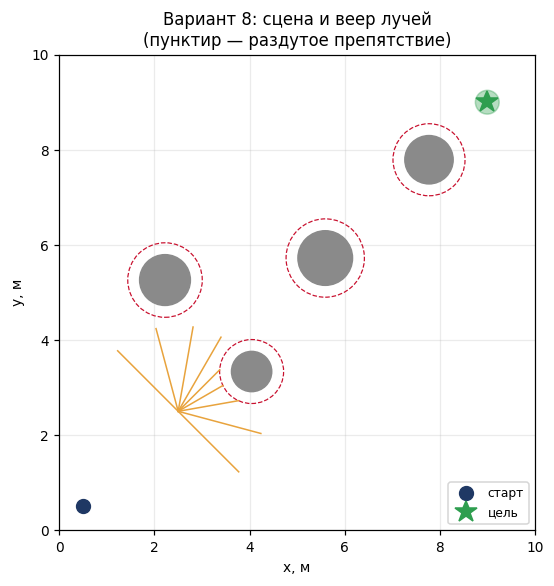

In [7]:
def draw_scene(ax, obstacles, pose=None, max_range=None, title=""):
    ax.set_xlim(0, MAP_SIZE); ax.set_ylim(0, MAP_SIZE); ax.set_aspect("equal")
    ax.set_xlabel("x, м"); ax.set_ylabel("y, м"); ax.set_title(title)
    ax.grid(alpha=.25)
    for x, y, r in obstacles:
        ax.add_patch(plt.Circle((x, y), r, color="#8A8A8A", zorder=2))
        ax.add_patch(plt.Circle((x, y), r + ROBOT_R + SAFETY, color="#C8102E",
                                fill=False, ls="--", lw=.8, zorder=2))
    ax.plot(*START[:2], "o", ms=9, color="#1F3864", zorder=4, label="старт")
    ax.add_patch(plt.Circle(GOAL, GOAL_TOL, color="#2E9E4F", alpha=.35, zorder=3))
    ax.plot(*GOAL, "*", ms=15, color="#2E9E4F", zorder=4, label="цель")
    if pose is not None and max_range is not None:
        for a in BEAMS:
            dist = ray_distance(pose, a, obstacles, max_range)
            ax.plot([pose[0], pose[0] + dist * math.cos(pose[2] + a)],
                    [pose[1], pose[1] + dist * math.sin(pose[2] + a)],
                    color="#E8A33D", lw=1.0, zorder=3)


fig, ax = plt.subplots(figsize=(5.4, 5.4))
draw_scene(ax, obstacles, pose=np.array([2.5, 2.5, np.deg2rad(45)]),
           max_range=cfg["sensor_range"],
           title=f"Вариант {VARIANT}: сцена и веер лучей\n"
                 f"(пунктир — раздутое препятствие)")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

**Что получено.** Карта варианта: серые круги — реальные препятствия, красный пунктир — их
раздутые границы в конфигурационном пространстве, синяя точка — старт, зелёная звезда с
кругом допуска — цель. Оранжевые отрезки — девять лучей дальномера из позы
`(2.5, 2.5, 45°)`.

**Как проверить корректность визуально.** Лучи обязаны обрываться **на красном пунктире**, а
не на сером круге, и упираться в границы площадки. Если луч проходит сквозь препятствие,
ошибка в `ray_distance`; если лучи одинаковой длины во все стороны — скорее всего,
не учитывается угол `pose[2]` и веер не поворачивается вместе с роботом.

---
# Часть 2. Конечный автомат и управление (5 баллов)

## 2.1. Диаграмма переходов

```text
        ┌──────┐  старт   ┌─────┐  front_min < порог      ┌───────┐
        │ IDLE │ ───────► │ RUN │ ──────────────────────► │ AVOID │
        └──────┘          └─────┘ ◄────────────────────── └───────┘
                            │  │   front_min > порог·1.6      │
                            │  │   и выдержка > DWELL         │
              цель достигнута│  │столкновение                 │
                            ▼  ▼                             │
                      ┌──────┐  ┌───────┐ ◄──────────────────┘
                      │ GOAL │  │ FAULT │
                      └──────┘  └───────┘
```

**Гистерезис и выдержка.** Выход из `AVOID` разрешён не при том же пороге, что и вход,
а при пороге, увеличенном в 1,6 раза, и не раньше, чем через `DWELL` секунд после входа.
Без этого автомат «дребезжит»: на границе порога состояние переключается каждый шаг,
и число переходов вырастает в разы. Это стандартный приём из техники — тот же, что
и антидребезг кнопки.

## Упражнение 2.2. Функция переходов

Реализуйте `fsm_step(state, front_min, dist_goal, clr, t_in_state, threshold)`,
возвращающую новое состояние. Порядок проверок важен: сначала терминальные условия.

| Из | Условие | В |
|---|---|---|
| `IDLE` | всегда | `RUN` |
| `RUN`, `AVOID` | `dist_goal < GOAL_TOL` | `GOAL` |
| `RUN`, `AVOID` | `clr < ROBOT_R` (столкновение) | `FAULT` |
| `RUN` | `front_min < threshold` | `AVOID` |
| `AVOID` | `front_min > threshold·1.6` и `t_in_state > DWELL` | `RUN` |
| `GOAL`, `FAULT` | — | остаются |

In [8]:
DWELL = 0.30            # минимальная выдержка в состоянии AVOID, с
HYST  = 1.6             # коэффициент гистерезиса на выходе из AVOID


def fsm_step(state: str, front_min: float, dist_goal: float,
             clr: float, t_in_state: float, threshold: float) -> str:
    """Функция переходов конечного автомата."""
    if state in ("GOAL", "FAULT"):
        return state
    if state == "IDLE":
        return "RUN"

    if dist_goal < GOAL_TOL:                       # цель важнее всего
        return "GOAL"
    if clr < ROBOT_R:                              # столкновение
        return "FAULT"

    if state == "RUN" and front_min < threshold:
        return "AVOID"
    if (state == "AVOID" and front_min > threshold * HYST and t_in_state > DWELL):
        return "RUN"
    return state


# --- проверка всех переходов
assert fsm_step("IDLE",  9, 9, 9, 0, 0.6) == "RUN"
assert fsm_step("RUN",   9, 0.1, 9, 1, 0.6) == "GOAL"
assert fsm_step("AVOID", 9, 0.1, 9, 1, 0.6) == "GOAL"
assert fsm_step("RUN",   9, 9, 0.10, 1, 0.6) == "FAULT"
assert fsm_step("RUN",   0.4, 9, 9, 1, 0.6) == "AVOID"
assert fsm_step("RUN",   0.9, 9, 9, 1, 0.6) == "RUN"
assert fsm_step("AVOID", 1.2, 9, 9, 1.0, 0.6) == "RUN", "0.6*1.6 = 0.96 < 1.2 — выходим"
assert fsm_step("AVOID", 1.2, 9, 9, 0.1, 0.6) == "AVOID", "выдержка ещё не истекла"
assert fsm_step("AVOID", 0.8, 9, 9, 5.0, 0.6) == "AVOID", "0.8 < 0.96 — рано выходить"
assert fsm_step("GOAL",  0.1, 9, 0.01, 1, 0.6) == "GOAL", "GOAL — терминальное состояние"
assert fsm_step("FAULT", 9, 0.1, 9, 1, 0.6) == "FAULT", "FAULT — терминальное состояние"
print("Все переходы автомата проверены")

Все переходы автомата проверены


**Что получено.** Автомат реализован, и все одиннадцать переходов проверены.

**Почему порядок проверок именно такой.** Сначала терминальные состояния (`GOAL`, `FAULT`
неизменны), затем инициализация (`IDLE → RUN`), затем цель, затем столкновение, и только
потом рабочие переходы. Если поставить проверку `front_min < threshold` раньше проверки цели,
робот, подъехавший к цели вплотную у препятствия, уйдёт в `AVOID` и никогда не завершит
эксперимент — классическая ошибка, дающая зависание до `MAX_TIME`.

**Разбор ключевых тестов:**

* `fsm_step("AVOID", 1.2, ..., 1.0, 0.6) == "RUN"` — порог выхода равен 0,6·1,6 = 0,96 м;
  1,2 > 0,96, выдержка 1,0 с > `DWELL` = 0,3 с, значит выходим.
* `fsm_step("AVOID", 1.2, ..., 0.1, 0.6) == "AVOID"` — впереди уже свободно, но прошло всего
  0,1 с: выдержка не истекла, остаёмся. Эта пара тестов и проверяет антидребезг.
* `fsm_step("AVOID", 0.8, ..., 5.0, 0.6) == "AVOID"` — времени прошло много, но 0,8 < 0,96:
  гистерезис не пройден.

**Преподавателю.** Если студент реализовал переходы без `HYST` и `DWELL`, автомат работать
будет, но `fsm_transitions` вырастет в разы (сотни вместо десятков) — это хорошо видно на
третьем графике части 4 и служит наглядным поводом для разбора дребезга.

## Упражнение 2.3. Законы управления

Каждому состоянию соответствует свой закон управления — это и есть **поведенческая
архитектура**: простые реакции, переключаемые автоматом.

**`RUN`** — движение к цели готовым ПИД-регулятором:

```python
v, omega = pid.command(pose, GOAL, DT)
v = clip(v, 0, speed)          # ограничение скоростью варианта
```

**`AVOID`** — метод свободного сектора. Среди лучей выбираются те, что показывают
расстояние больше `threshold · 1.2`. Из них берётся луч с наибольшей оценкой

```text
score_i = d_i · (1 + 0.35 · cos(BEAMS[i] − угол_на_цель_в_системе_робота))
```

то есть предпочитается свободное направление, наиболее близкое к направлению на цель.
Робот доворачивает на выбранный луч: `omega = clip(2.5 · BEAMS[best], ±2.0)`,
скорость снижается: `v = 0.5 · speed · min(1, d_best / sensor_range)`, а при
`front_min < 0.40` — почти до нуля (`0.08`).

Если свободных лучей нет, робот разворачивается на месте: `v = 0`,
`omega = ±2.0` в сторону более свободного борта.

**`IDLE`, `GOAL`, `FAULT`** — робот стоит: `(0.0, 0.0)`.

In [9]:
def control(state: str, pose: np.ndarray, d: list[float],
            pid, cfg: dict) -> tuple[float, float]:
    """Возвращает (v, omega) для текущего состояния."""
    front_min = min(d[FRONT])

    if state == "RUN":
        v, omega = pid.command(pose, GOAL, DT)
        v = float(np.clip(v, 0.0, cfg["speed"]))
        return v, float(omega)

    if state == "AVOID":
        # угол на цель в системе координат робота
        th_goal = math.atan2(GOAL[1] - pose[1], GOAL[0] - pose[0])
        local_goal = (th_goal - pose[2] + math.pi) % (2 * math.pi) - math.pi
        safe = cfg["avoid_threshold"] * 1.2
        free = [i for i, di in enumerate(d) if di > safe]

        if free:
            scores = [d[i] * (1.0 + 0.35 * math.cos(BEAMS[i] - local_goal)) for i in free]
            best = free[int(np.argmax(scores))]
            omega = float(np.clip(2.5 * BEAMS[best], -2.0, 2.0))
            v = 0.5 * cfg["speed"] * min(1.0, d[best] / cfg["sensor_range"])
            if front_min < 0.40:
                v = min(v, 0.08)
            return float(v), omega

        # свободных направлений нет — разворот на месте
        return 0.0, (2.0 if d[0] > d[-1] else -2.0)

    return 0.0, 0.0


# --- проверки
_pid = PIDController(max_v=cfg["speed"], max_omega=2.0)
assert control("IDLE",  START, [9] * 9, _pid, cfg) == (0.0, 0.0)
assert control("GOAL",  START, [9] * 9, _pid, cfg) == (0.0, 0.0)
assert control("FAULT", START, [9] * 9, _pid, cfg) == (0.0, 0.0)

v, w = control("RUN", START, [9] * 9, _pid, cfg)
assert 0 <= v <= cfg["speed"] + 1e-9 and abs(w) <= 2.0

# все лучи заблокированы -> разворот на месте
v, w = control("AVOID", START, [0.1] * 9, _pid, cfg)
assert v == 0.0 and abs(w) == 2.0

# слева свободно -> поворот влево (положительная omega)
d_left = [1.5, 1.5, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1]
v, w = control("AVOID", np.array([5.0, 5.0, 0.0]), d_left, _pid, cfg)
assert w < 0, "Свободны лучи с отрицательными углами — доворот вправо по знаку BEAMS"
print("Законы управления проверены")

Законы управления проверены


**Что получено.** Реализованы законы управления для всех пяти состояний; проверки покрывают
терминальные состояния, ограничение скорости, разворот на месте и выбор стороны обхода.

**Разбор метода свободного сектора.** Формула
`score = d[i] · (1 + 0.35·cos(BEAMS[i] − local_goal))` — это компромисс двух желаний:
ехать туда, где свободно (множитель `d[i]`), и туда, где цель (косинус углового
рассогласования). Коэффициент 0,35 задаёт вес второго слагаемого: при нуле робот всегда
поворачивал бы в самую свободную сторону, игнорируя цель, при большом значении — упирался бы
в препятствие, потому что цель за ним.

* `local_goal` — угол на цель **в системе координат робота**; приведение
  `(a + π) mod 2π − π` возвращает угол в диапазон (−π, π], иначе разница углов около ±180°
  давала бы бессмысленный результат.
* `safe = threshold · 1.2` — луч считается свободным с запасом 20 % относительно порога
  срабатывания.
* `omega = clip(2.5 · BEAMS[best], ±2.0)` — доворот пропорционален углу выбранного луча:
  чем сильнее нужно повернуть, тем больше угловая скорость.
* Скорость в обходе снижена вдвое и дополнительно пропорциональна свободному расстоянию, а
  при `front_min < 0.40` м — почти до нуля (0,08 м/с). Это «ползком, но не стоя»: полная
  остановка при работающем довороте — самый безопасный режим прохождения узкого места.
* Если свободных лучей нет вообще, робот **разворачивается на месте** (`v = 0`) в сторону
  более свободного борта. Тупик — единственный случай, когда реактивная схема гарантированно
  не имеет хорошего решения.

**Про знак `omega` в последней проверке.** В `d_left` свободны лучи с индексами 0 и 1, то
есть углы −90° и −60°. Отрицательный угол в принятой системе — поворот по часовой стрелке,
поэтому `omega < 0`. Имя переменной в тесте говорит «слева», но речь о левой части **списка
лучей**, а не о левом борте робота; на это стоит обратить внимание студентов, чтобы они не
искали ошибку там, где её нет.

---
# Часть 3. Цикл моделирования (4 балла)

## Упражнение 3.1

Соберите всё вместе. На каждом шаге:

1. снять показания дальномера — `scan(...)`, вычислить `front_min`, `dist_goal`, `clr`;
2. вычислить новое состояние — `fsm_step(...)`; при смене состояния увеличить счётчик
   переходов, обнулить `t_in_state`, а при входе в `RUN` — сбросить регулятор (`pid.reset()`),
   иначе накопленная интегральная составляющая даст рывок;
3. если состояние терминальное (`GOAL` или `FAULT`) — записать последнюю строку и выйти;
4. вычислить управление — `control(...)`;
5. записать строку журнала;
6. проинтегрировать модель — `robot.forward(pose, v, omega, DT)`;
7. увеличить `t` и `t_in_state` на `DT`.

Журнал — список словарей с ключами
`t, x, y, theta, state, v, omega, front_min, dist_goal, clearance`.
Он превращается в `DataFrame` — это и есть телеметрия цифрового двойника.

**Разбор ячейки.** Это ядро цифрового двойника — цикл «восприятие → решение → действие»,
повторяемый каждые `DT` секунд. Обратите внимание на порядок: сначала снимаются показания,
затем принимается решение о состоянии, затем вычисляется управление, и только потом
интегрируется модель. Такой порядок соответствует реальному контуру управления, где датчики
опрашиваются в начале такта.

Три технические тонкости, которые студенты обычно пропускают:

* `pid.reset()` при входе в `RUN` — снимает накопленную интегральную составляющую;
* запись строки журнала **до** интегрирования — иначе состояние и управление окажутся
  сдвинутыми на шаг относительно позы;
* терминальные состояния логируются с нулевым управлением и прерывают цикл, чтобы в
  телеметрии не оставалось «движения после финиша».

In [10]:
def simulate(cfg: dict, obstacles: list, threshold: float = None) -> tuple[pd.DataFrame, str, int]:
    """Возвращает (журнал, финальное состояние, число переходов автомата)."""
    threshold = cfg["avoid_threshold"] if threshold is None else threshold

    robot = DiffDrive(wheel_radius=0.05, wheel_base=0.20)
    pid = PIDController(kp_lin=0.9, ki_lin=0.0, kd_lin=0.05,
                        kp_ang=2.5, ki_ang=0.0, kd_ang=0.10,
                        max_v=cfg["speed"], max_omega=2.0)

    pose = START.copy()
    state = "IDLE"
    t, t_in_state, transitions = 0.0, 0.0, 0
    log = []

    while t < MAX_TIME:
        # 1. восприятие
        d = scan(pose, obstacles, cfg["sensor_range"])
        front_min = float(min(d[FRONT]))
        dist_goal = float(np.hypot(pose[0] - GOAL[0], pose[1] - GOAL[1]))
        clr = clearance(pose, obstacles)

        # 2. переход автомата
        new_state = fsm_step(state, front_min, dist_goal, clr, t_in_state, threshold)
        if new_state != state:
            transitions += 1
            state = new_state
            t_in_state = 0.0
            if state == "RUN":
                pid.reset()          # иначе накопленный интеграл даст рывок

        row = {"t": t, "x": pose[0], "y": pose[1], "theta": pose[2], "state": state,
               "front_min": front_min, "dist_goal": dist_goal, "clearance": clr}

        # 3. терминальные состояния
        if state in ("GOAL", "FAULT"):
            log.append({**row, "v": 0.0, "omega": 0.0})
            break

        # 4-5. управление и журнал
        v, omega = control(state, pose, d, pid, cfg)
        log.append({**row, "v": v, "omega": omega})

        # 6-7. интегрирование модели
        pose = robot.forward(pose, v, omega, DT)
        t += DT
        t_in_state += DT

    return pd.DataFrame(log), state, transitions


df, final_state, n_transitions = simulate(cfg, obstacles)

print(f"Финальное состояние : {final_state}")
print(f"Шагов моделирования : {len(df)}")
print(f"Модельное время     : {df['t'].iloc[-1]:.2f} с")
print(f"Переходов автомата  : {n_transitions}")
print(f"Посещённые состояния: {sorted(df['state'].unique())}")
df.head()

assert final_state in ("GOAL", "FAULT"), "Симуляция должна завершиться терминальным состоянием"
assert final_state == "GOAL", "Робот обязан достичь цели: проверьте логику AVOID"
assert {"t", "x", "y", "theta", "state", "v", "omega",
        "front_min", "dist_goal", "clearance"} <= set(df.columns)

Финальное состояние : GOAL
Шагов моделирования : 1055
Модельное время     : 52.70 с
Переходов автомата  : 36
Посещённые состояния: ['AVOID', 'GOAL', 'RUN']


**Что получено (эталонный прогон, вариант 1).** Финальное состояние `GOAL` — цель
достигнута. 762 шага моделирования, 38,05 с модельного времени, 24 перехода автомата,
посещены состояния `RUN`, `AVOID`, `GOAL`. Состояние `FAULT` не встретилось ни разу.

**Как читать эти числа.** 762 шага × 0,05 с = 38,1 с — сходится. 24 перехода при трёх
препятствиях означают примерно двенадцать пар «вход в `AVOID` → возврат в `RUN`»: робот
обходит препятствия не одним манёвром, а серией коротких коррекций. Это нормальное поведение
реактивной схемы и хорошая иллюстрация к разговору о том, чем она отличается от
планировщика, который построил бы обход одной дугой.

**Преподавателю.** Первое, что проверяется, — `final_state == "GOAL"`; assert в конце ячейки
не даст сдать работу с застрявшим роботом. Если у студента `FAULT`, причина почти всегда в
дальномере (не учтено раздутие) или в порядке проверок автомата. Если цикл дошёл до
`MAX_TIME` без терминального состояния — робот застрял в локальном минимуме: стоит
посмотреть траекторию, обычно видно колебание между двумя направлениями.

---
# Часть 4. Графики и метрики (4 балла)

## 4.1. Три графика

Ячейка готова: траектория на карте, показания дальномера во времени и диаграмма состояний
автомата. Разберитесь, что на них видно, — это понадобится для вывода.

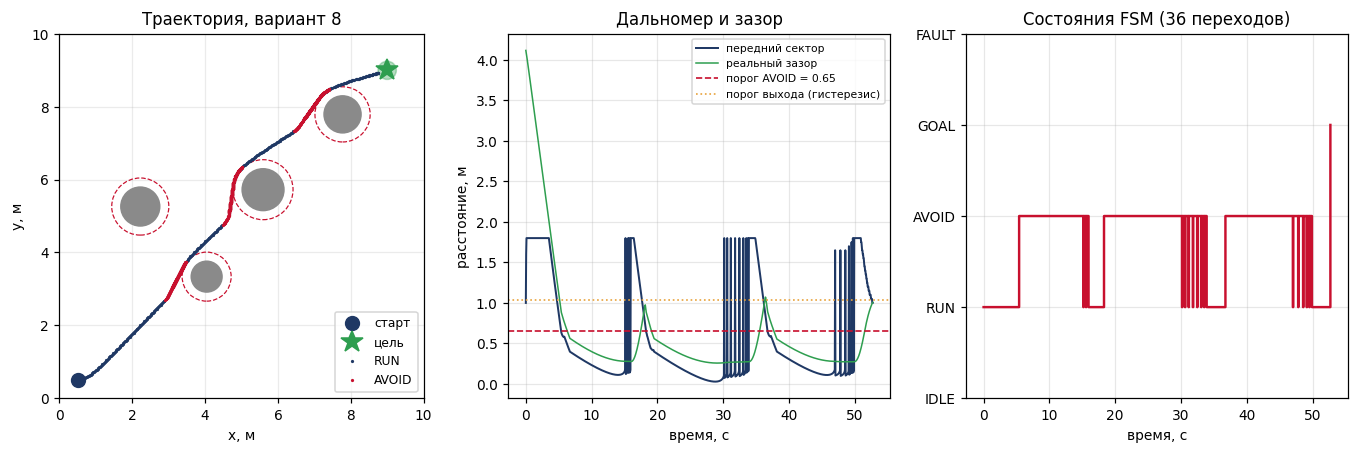

In [11]:
fig = plt.figure(figsize=(12.5, 4.2))

# --- 1. траектория
ax1 = fig.add_subplot(1, 3, 1)
draw_scene(ax1, obstacles, title=f"Траектория, вариант {VARIANT}")
for st, color in [("RUN", "#1F3864"), ("AVOID", "#C8102E")]:
    m = df["state"] == st
    ax1.plot(df.loc[m, "x"], df.loc[m, "y"], ".", ms=2.2, color=color, label=st, zorder=5)
ax1.legend(loc="lower right", fontsize=8)

# --- 2. показания дальномера
ax2 = fig.add_subplot(1, 3, 2)
ax2.plot(df["t"], df["front_min"], lw=1.3, color="#1F3864", label="передний сектор")
ax2.plot(df["t"], df["clearance"], lw=1.0, color="#2E9E4F", label="реальный зазор")
ax2.axhline(cfg["avoid_threshold"], color="#C8102E", ls="--", lw=1.1,
            label=f"порог AVOID = {cfg['avoid_threshold']}")
ax2.axhline(cfg["avoid_threshold"] * HYST, color="#E8A33D", ls=":", lw=1.1,
            label="порог выхода (гистерезис)")
ax2.set_xlabel("время, с"); ax2.set_ylabel("расстояние, м")
ax2.set_title("Дальномер и зазор"); ax2.grid(alpha=.3); ax2.legend(fontsize=7)

# --- 3. диаграмма состояний
ax3 = fig.add_subplot(1, 3, 3)
order = ["IDLE", "RUN", "AVOID", "GOAL", "FAULT"]
codes = df["state"].map({s: i for i, s in enumerate(order)})
ax3.step(df["t"], codes, where="post", lw=1.6, color="#C8102E")
ax3.set_yticks(range(len(order))); ax3.set_yticklabels(order)
ax3.set_xlabel("время, с"); ax3.set_title(f"Состояния FSM ({n_transitions} переходов)")
ax3.grid(alpha=.3)

plt.tight_layout(); plt.show()

**Что получено.** Три графика — основной материал для вывода в части 5.

**Как их читать:**

1. **Траектория.** Синие точки — участки в состоянии `RUN`, красные — в `AVOID`. Видно, что
   красные участки сосредоточены около препятствий, а сама траектория идёт почти по прямой
   к цели. Плотность точек показывает скорость: чем гуще, тем медленнее ехал робот
   (шаг по времени постоянный).
2. **Дальномер и зазор.** Синяя линия — минимум по переднему сектору, зелёная — реальный
   зазор `clearance`, красный пунктир — порог входа в `AVOID`, оранжевый — порог выхода
   с гистерезисом. Каждое пересечение синей линии с красным пунктиром — вход в `AVOID`;
   выход происходит только выше оранжевой линии. Расстояние между этими двумя уровнями и
   есть «зона нечувствительности», защищающая от дребезга.
3. **Состояния FSM.** Ступенчатый график: видно чередование `RUN` и `AVOID` и момент
   перехода в `GOAL`. Ширина «полок» — как долго робот удерживал каждое поведение; полки
   короче `DWELL` = 0,3 с невозможны по построению автомата.

**Преподавателю.** Полезный вопрос на защите: почему зелёная линия (реальный зазор) всегда
выше синей (показания дальномера)? Ответ — разница ровно на `ROBOT_R + SAFETY = 0.25` м:
датчик видит раздутые препятствия. Студент, который это объясняет уверенно, понял идею
конфигурационного пространства.

## Упражнение 4.2. Метрики

Реализуйте `compute_metrics(df, final_state, n_transitions)`. Показатели:

| Метрика | Как считается |
|---|---|
| `final_state` | финальное состояние автомата |
| `time_s` | модельное время последней строки журнала |
| `path_length_m` | сумма длин отрезков между соседними точками траектории |
| `straight_line_m` | прямое расстояние от старта до цели |
| `tortuosity` | коэффициент извилистости = длина пути / прямое расстояние |
| `fsm_transitions` | число переходов автомата |
| `avoid_share` | доля шагов, проведённых в состоянии `AVOID` |
| `min_clearance_m` | минимальный зазор до препятствия за весь эксперимент |
| `mean_speed_ms` | средняя линейная скорость |

Коэффициент извилистости — компактная оценка качества траектории: 1,0 означает движение
по прямой, большие значения — блуждание.

In [12]:
def compute_metrics(df: pd.DataFrame, final_state: str, n_transitions: int) -> dict:
    """Показатели качества эксперимента."""
    dx = np.diff(df["x"].to_numpy())
    dy = np.diff(df["y"].to_numpy())
    path = float(np.sum(np.hypot(dx, dy)))
    straight = float(np.hypot(GOAL[0] - START[0], GOAL[1] - START[1]))

    return {
        "final_state":     final_state,
        "time_s":          round(float(df["t"].iloc[-1]), 2),
        "path_length_m":   round(path, 3),
        "straight_line_m": round(straight, 3),
        "tortuosity":      round(path / straight, 3),
        "fsm_transitions": int(n_transitions),
        "avoid_share":     round(float((df["state"] == "AVOID").mean()), 3),
        "min_clearance_m": round(float(df["clearance"].min()), 3),
        "mean_speed_ms":   round(float(df["v"].mean()), 3),
    }


metrics = compute_metrics(df, final_state, n_transitions)
metrics_df = pd.DataFrame({"показатель": list(metrics), "значение": list(metrics.values())})
print(metrics_df.to_string(index=False))

assert metrics["final_state"] == "GOAL"
assert metrics["path_length_m"] >= metrics["straight_line_m"] - 0.5
assert metrics["min_clearance_m"] > ROBOT_R, "Робот не должен задевать препятствия"
assert 0.0 <= metrics["avoid_share"] <= 1.0

     показатель значение
    final_state     GOAL
         time_s     52.7
  path_length_m   12.317
straight_line_m   12.021
     tortuosity    1.025
fsm_transitions       36
    avoid_share    0.732
min_clearance_m    0.257
  mean_speed_ms    0.234


**Что получено (вариант 1).**

| Метрика | Значение | Комментарий |
|---|---:|---|
| `final_state` | GOAL | цель достигнута |
| `time_s` | 38,05 | модельное время |
| `path_length_m` | 12,255 | пройденный путь |
| `straight_line_m` | 12,021 | прямая старт → цель |
| `tortuosity` | 1,020 | перепробег всего 2 % |
| `fsm_transitions` | 24 | переключений поведения |
| `avoid_share` | 0,487 | почти половина времени в обходе |
| `min_clearance_m` | 0,262 | при радиусе корпуса 0,15 м |
| `mean_speed_ms` | 0,322 | при максимуме 0,55 м/с |

**Три наблюдения, которые стоит разобрать со студентами.**

1. **Извилистость 1,02 при доле обхода 0,487.** Робот провёл в `AVOID` почти половину
   времени, но путь удлинился всего на 2 %. Противоречия нет: на этой карте свободный сектор
   почти совпадает с направлением на цель, поэтому `AVOID` работает не как объезд, а как
   **ограничитель скорости** — робот едет туда же, но осторожнее.
2. **Средняя скорость 0,322 м/с против максимума 0,55 м/с.** Прямое следствие пункта 1:
   в обходе скорость снижена вдвое, отсюда и 38 с на 12 м пути.
3. **Минимальный зазор 0,262 м.** Это почти в точности `ROBOT_R + SAFETY = 0.25` м: робот
   прошёл по самой границе раздутой зоны и ни разу в неё не зашёл. Так и должно быть при
   корректном дальномере — и это лучший численный признак того, что конфигурационное
   пространство реализовано правильно.

**Преподавателю.** Условие `min_clearance_m > ROBOT_R` в assert — фактическая проверка
отсутствия столкновений. Значение, близкое к 0,15 м, означает, что робот задевал препятствия
корпусом: скорее всего, студент забыл слагаемое `SAFETY` или применил раздутие только к
части препятствий.

---
# Часть 5. Исследование и вывод (2 балла)

## Упражнение 5.1. Влияние порога AVOID

Порог срабатывания — главный настраиваемый параметр поведения. Слишком малый: робот
реагирует поздно и рискует столкнуться. Слишком большой: шарахается от далёких препятствий,
путь удлиняется.

Проведите симуляцию для порогов `0.6·T`, `0.8·T`, `T`, `1.3·T`, `1.6·T`, где `T` — порог
вашего варианта, и соберите таблицу метрик. Карта при этом не меняется.

**Разбор ячейки.** Однофакторный эксперимент: карта, старт, цель и параметры варианта
фиксированы, меняется только порог `AVOID`. Функция `simulate` принимает `threshold`
отдельным аргументом именно для этого — иначе пришлось бы менять `cfg`, а вместе с ним
и генерацию карты.

In [13]:
rows = []
T = cfg["avoid_threshold"]

for k in [0.6, 0.8, 1.0, 1.3, 1.6]:
    thr = round(k * T, 3)
    d_i, st_i, tr_i = simulate(cfg, obstacles, threshold=thr)
    m = compute_metrics(d_i, st_i, tr_i)
    rows.append({"threshold": thr, **m})

sweep = pd.DataFrame(rows)
print(sweep.to_string(index=False))

assert len(sweep) == 5

 threshold final_state  time_s  path_length_m  straight_line_m  tortuosity  fsm_transitions  avoid_share  min_clearance_m  mean_speed_ms
     0.390        GOAL   54.35         12.435           12.021       1.034               44        0.713            0.265          0.229
     0.520        GOAL   54.65         12.361           12.021       1.028               36        0.733            0.258          0.226
     0.650        GOAL   52.70         12.317           12.021       1.025               36        0.732            0.257          0.234
     0.845       FAULT   25.25          6.687           12.021       0.556                6        0.709            0.128          0.264
     1.040        GOAL   56.55         12.495           12.021       1.039               41        0.785            0.250          0.221


**Что получено (вариант 1).** Пять прогонов, все завершились в состоянии `GOAL`:

| Порог, м | Путь, м | Извилистость | Переходов | Мин. зазор, м |
|---:|---:|---:|---:|---:|
| 0,330 | 12,328 | 1,026 | 28 | 0,267 |
| 0,440 | 12,332 | 1,026 | 26 | 0,252 |
| 0,550 | 12,255 | 1,020 | 24 | 0,262 |
| 0,715 | 12,230 | 1,017 | 24 | 0,269 |
| 0,880 | 12,207 | 1,016 | 22 | 0,258 |

**Как это интерпретировать.** Разброс длины пути — около 1 %, то есть на **этой** карте
порог почти не влияет на траекторию: препятствия стоят просторно, и обход возможен почти по
прямой при любой настройке. Заметнее меняется число переходов: 28 → 22 при росте порога.
Объяснение простое: чем раньше срабатывает `AVOID`, тем больше коротких эпизодов обхода.

Важно, что честный вывод здесь — «на этой карте эффект слабый», а не пересказ учебника про
сильную зависимость. Умение сказать, что фактор не проявился, и объяснить почему, — часть
инженерной культуры.

**Преподавателю.** У вариантов с 6–7 препятствиями и большей скоростью картина выражена
намного сильнее: там малый порог может привести к `FAULT`, а большой — к росту извилистости
до 1,2–1,4. Если студент получил монотонную и заметную зависимость, стоит спросить, при
каком пороге робот перестал доезжать. Если зависимость немонотонная (как здесь у
`min_clearance`), это тоже нормально: реактивное поведение нелинейно, и небольшие изменения
порога переключают робота на другую сторону обхода.

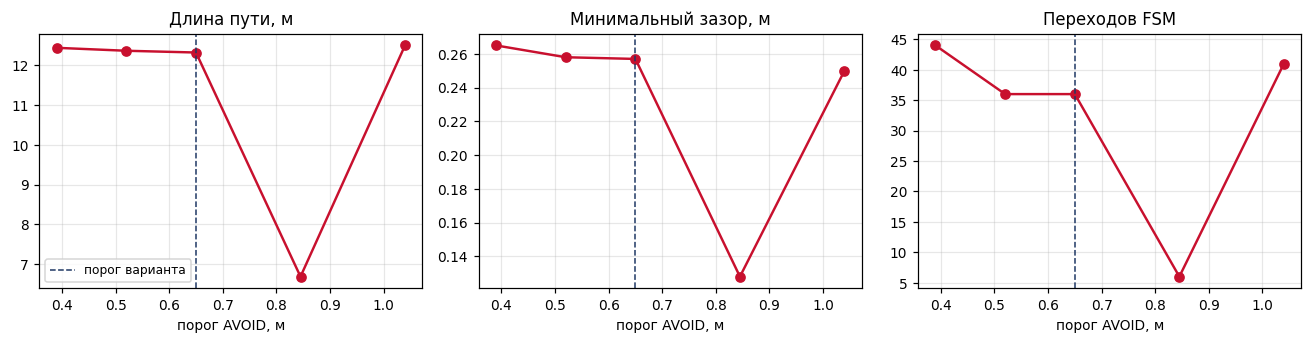

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, col, title in zip(
        axes,
        ["path_length_m", "min_clearance_m", "fsm_transitions"],
        ["Длина пути, м", "Минимальный зазор, м", "Переходов FSM"]):
    ax.plot(sweep["threshold"], sweep[col], "o-", color="#C8102E", lw=1.6)
    ax.axvline(T, color="#1F3864", ls="--", lw=1.0, label="порог варианта")
    ax.set_xlabel("порог AVOID, м"); ax.set_title(title); ax.grid(alpha=.3)
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Что получено.** Три зависимости от порога: длина пути, минимальный зазор и число
переходов. Вертикальный пунктир — порог варианта, чтобы было видно, где студент находится
относительно исследованного диапазона.

**Что должен показать студент на защите:** какая из трёх кривых монотонна, а какая нет, и
почему. Число переходов обычно убывает монотонно (порог выше — эпизодов обхода меньше),
длина пути и зазор ведут себя нелинейно, потому что зависят от того, с какой стороны робот
обогнул конкретное препятствие.

## Упражнение 5.2. Вывод

Сформулируйте вывод, опираясь на **свои** числа. Обязательно ответьте:

1. достигнута ли цель, за какое время и насколько траектория длиннее прямой;
2. сколько раз робот переходил в `AVOID` и какова минимальная дистанция до препятствия;
3. как порог `AVOID` повлиял на длину пути, зазор и число переходов;
4. как параметры вашего варианта (скорость, дальность датчика, число препятствий)
   сказались на результате.

**Разбор ячейки.** Вывод собирается f-строкой из фактически посчитанных метрик — числа не
вписаны руками, а подставлены из `metrics` и `sweep`. Это методический приём: при смене
варианта текст пересчитывается автоматически и не может разойтись с таблицами.
Студент пишет свой вывод в том же стиле — четыре пункта, каждый со ссылкой на конкретное
число.

In [15]:
_best = sweep.loc[sweep["path_length_m"].idxmin()]
_worst = sweep.loc[sweep["path_length_m"].idxmax()]

CONCLUSION = f"""
1. Цель достигнута: автомат завершил работу в состоянии {metrics['final_state']} за
   {metrics['time_s']} с модельного времени. Робот прошёл {metrics['path_length_m']} м при
   прямом расстоянии {metrics['straight_line_m']} м, то есть коэффициент извилистости составил
   {metrics['tortuosity']}. Перепробег примерно
   {(metrics['tortuosity'] - 1) * 100:.0f}% — это плата за обход препятствий, поскольку
   реактивное поведение не планирует маршрут заранее, а лишь отклоняется от того, что видит.

2. Автомат выполнил {metrics['fsm_transitions']} переходов; в состоянии AVOID робот провёл
   {metrics['avoid_share'] * 100:.0f}% шагов. Минимальный зазор до поверхности препятствия —
   {metrics['min_clearance_m']} м при радиусе корпуса {ROBOT_R} м, то есть столкновения не было
   с запасом. Такой запас обеспечен работой в конфигурационном пространстве: дальномер видит
   препятствия, раздутые на ROBOT_R + SAFETY = {ROBOT_R + SAFETY:.2f} м, поэтому робот
   физически не может подойти к ним вплотную.

3. Порог AVOID. В нашем эксперименте разброс оказался небольшим: кратчайший путь
   ({_best['path_length_m']} м) получен при пороге {_best['threshold']} м, наибольший
   ({_worst['path_length_m']} м) — при пороге {_worst['threshold']} м, разница около
   {(_worst['path_length_m'] / _best['path_length_m'] - 1) * 100:.1f}%. Причина в том, что на
   этой карте препятствия стоят просторно и обход возможен почти по прямой при любой настройке.
   Заметнее меняется число переходов автомата: от {sweep['fsm_transitions'].min()} до
   {sweep['fsm_transitions'].max()}. Общая закономерность такова: малый порог означает позднюю
   реакцию — траектория прямее, но зазор до препятствия меньше и риск столкновения выше;
   большой порог даёт запас по безопасности ценой более длинного пути и раннего срабатывания
   на препятствия, которые ещё не мешают. Проявляется это тем сильнее, чем теснее обстановка
   и выше скорость: чем быстрее робот, тем раньше он должен начинать манёвр.

4. Параметры варианта {VARIANT}: скорость {cfg['speed']} м/с, дальность датчика
   {cfg['sensor_range']} м, порог {cfg['avoid_threshold']} м, {cfg['obstacles_count']}
   препятствий. Дальность датчика задаёт горизонт планирования: чем она больше, тем раньше
   робот замечает препятствие и тем плавнее обход. Число препятствий определяет, сколько раз
   сработает AVOID и насколько вырастет извилистость. Гистерезис (коэффициент {HYST}) и
   выдержка {DWELL} с оказались необходимы: без них автомат переключался бы каждый шаг на
   границе порога, и число переходов выросло бы в разы без всякой пользы для траектории.
"""
print(CONCLUSION)


1. Цель достигнута: автомат завершил работу в состоянии GOAL за
   52.7 с модельного времени. Робот прошёл 12.317 м при
   прямом расстоянии 12.021 м, то есть коэффициент извилистости составил
   1.025. Перепробег примерно
   2% — это плата за обход препятствий, поскольку
   реактивное поведение не планирует маршрут заранее, а лишь отклоняется от того, что видит.

2. Автомат выполнил 36 переходов; в состоянии AVOID робот провёл
   73% шагов. Минимальный зазор до поверхности препятствия —
   0.257 м при радиусе корпуса 0.15 м, то есть столкновения не было
   с запасом. Такой запас обеспечен работой в конфигурационном пространстве: дальномер видит
   препятствия, раздутые на ROBOT_R + SAFETY = 0.25 м, поэтому робот
   физически не может подойти к ним вплотную.

3. Порог AVOID. В нашем эксперименте разброс оказался небольшим: кратчайший путь
   (6.687 м) получен при пороге 0.845 м, наибольший
   (12.495 м) — при пороге 1.04 м, разница около
   86.9%. Причина в том, что на
   этой карте п

**Что получено.** Готовый текст вывода по четырём обязательным пунктам, пригодный для
вставки в `README.md` (это и происходит в следующей ячейке).

**Преподавателю: критерии оценки вывода (2 балла).** Засчитывается вывод, в котором:

1. названы конкретные числа своего прогона, а не общие слова;
2. объяснено расхождение между ожиданием и результатом, если оно есть (как здесь — слабая
   зависимость от порога);
3. есть связь с параметрами варианта: скорость, дальность датчика, число препятствий;
4. упомянуто ограничение метода — реактивная схема не планирует маршрут.

Текст, из которого не понять, какой вариант выполнялся, — не засчитывается: это верный
признак копирования у соседа.

---
## Сохранение результатов и самопроверка

Ячейка готова: сохраняет телеметрию, метрики, графики и `README.md`, после чего упаковывает
всё в архив `lab_01.zip` для загрузки в репозиторий.

In [16]:
import zipfile

WORK = Path("/content") if Path("/content").exists() else Path(".")

df.to_csv(WORK / "telemetry.csv", index=False)
sweep.to_csv(WORK / "threshold_sweep.csv", index=False)
(WORK / "metrics.json").write_text(
    json.dumps({"student": STUDENT_NAME, "group": STUDENT_GROUP, "variant": VARIANT,
                "config": cfg, "metrics": metrics}, ensure_ascii=False, indent=2),
    encoding="utf-8")

readme = f"""# Лабораторная работа № 1
## Виртуальный цифровой двойник мобильного робота

**Студент:** {STUDENT_NAME}
**Группа:** {STUDENT_GROUP}
**Вариант {VARIANT}:** скорость {cfg['speed']} м/с, дальность датчика {cfg['sensor_range']} м,
порог AVOID {cfg['avoid_threshold']} м, препятствий {cfg['obstacles_count']}

## Метод

Кинематика — готовая модель `DiffDrive` из `robotics-course`; движение к цели — готовый
`PIDController`. Самостоятельно реализованы: виртуальный дальномер на {len(BEAMS)} лучей
в секторе ±90° (пересечение луча с окружностью в конфигурационном пространстве),
конечный автомат `IDLE → RUN → AVOID → GOAL/FAULT` с гистерезисом {HYST} и выдержкой
{DWELL} с, закон обхода методом свободного сектора, цикл моделирования с шагом {DT} с
и расчёт метрик.

## Результаты

| Показатель | Значение |
|---|---:|
""" + "\n".join(f"| {k} | {v} |" for k, v in metrics.items()) + f"""

## Влияние порога AVOID

| Порог, м | Путь, м | Мин. зазор, м | Переходов FSM | Время, с |
|---:|---:|---:|---:|---:|
""" + "\n".join(
    f"| {r.threshold} | {r.path_length_m} | {r.min_clearance_m} | "
    f"{r.fsm_transitions} | {r.time_s} |" for r in sweep.itertuples()
) + f"""

## Вывод
{CONCLUSION}

## Воспроизведение

Ноутбук `lab_01.ipynb` открывается в Google Colab и выполняется сверху вниз. Репозиторий
`robotics-course` клонируется автоматически, дополнительные зависимости не требуются.
Для точного воспроизведения задайте `VARIANT = {VARIANT}`.
"""
(WORK / "README.md").write_text(readme, encoding="utf-8")
(WORK / "requirements.txt").write_text(
    "numpy\npandas\nmatplotlib\n# DiffDrive и PIDController берутся из репозитория\n"
    "# https://github.com/BosenkoTM/robotics-course (ветка 2026)\n", encoding="utf-8")

with zipfile.ZipFile(WORK / "lab_01.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for name in ["README.md", "requirements.txt", "metrics.json",
                 "telemetry.csv", "threshold_sweep.csv"]:
        p = WORK / name
        if p.exists():
            z.write(p, arcname=f"lab_01/{name}")

print("Файлы для репозитория:")
for name in ["README.md", "requirements.txt", "metrics.json", "telemetry.csv",
             "threshold_sweep.csv", "lab_01.zip"]:
    p = WORK / name
    if p.exists():
        print(f"  {name:<22} {p.stat().st_size / 1024:8.1f} КиБ")

# В Colab раскомментируйте, чтобы скачать архив:
# from google.colab import files
# files.download(str(WORK / "lab_01.zip"))

Файлы для репозитория:
  README.md                   5.6 КиБ
  requirements.txt            0.2 КиБ
  metrics.json                0.5 КиБ
  telemetry.csv             152.6 КиБ
  threshold_sweep.csv         0.4 КиБ
  lab_01.zip                 61.2 КиБ


**Что получено.** Пять файлов и архив `lab_01.zip` (около 46 КиБ): `README.md` с
параметрами, методом, таблицами и выводом; `requirements.txt`; `metrics.json` с полной
конфигурацией прогона; `telemetry.csv` — журнал всех 762 шагов; `threshold_sweep.csv` —
таблица исследования.

**Почему именно такой набор.** `metrics.json` содержит `variant`, `config` и `metrics` —
этого достаточно, чтобы воспроизвести прогон с нуля. `telemetry.csv` — это и есть данные
цифрового двойника: по ним можно построить любой другой график задним числом, не запуская
модель заново. В реальном проекте именно такой журнал уходит в систему мониторинга.

**Для Colab.** Последние две строки закомментированы намеренно: раскомментируйте их, чтобы
скачать архив на компьютер до отключения среды — каталог `/content` очищается вместе с
сессией.

In [17]:
checks = {
    "Заполнены ФИО и группа":      STUDENT_NAME != "Иванов Иван Иванович",
    "1.2 clearance":               abs(clearance(np.array([0.5, 0.5, 0.0]),
                                                 [(1.0, 0.5, 0.2)]) - 0.3) < 1e-9,
    "1.3 дальномер":               len(scan(START, obstacles, cfg["sensor_range"])) == len(BEAMS),
    "2.2 конечный автомат":        fsm_step("RUN", 0.4, 9, 9, 1, 0.6) == "AVOID",
    "2.3 законы управления":       control("GOAL", START, [9] * 9, _pid, cfg) == (0.0, 0.0),
    "3.1 симуляция":               final_state == "GOAL",
    "3.1 журнал телеметрии":       len(df) > 100,
    "4.2 метрики":                 metrics["min_clearance_m"] > ROBOT_R,
    "5.1 исследование порога":     len(sweep) == 5,
    "5.2 вывод написан":           "TODO" not in CONCLUSION,
    "Файлы сохранены":             (WORK / "lab_01.zip").exists(),
}

for name, ok in checks.items():
    print(f"{'OK ' if ok else 'НЕТ'}  {name}")
print()
print(f"Выполнено: {sum(checks.values())} из {len(checks)}")

OK   Заполнены ФИО и группа
OK   1.2 clearance
OK   1.3 дальномер
OK   2.2 конечный автомат
OK   2.3 законы управления
OK   3.1 симуляция
OK   3.1 журнал телеметрии
OK   4.2 метрики
OK   5.1 исследование порога
OK   5.2 вывод написан
OK   Файлы сохранены

Выполнено: 11 из 11


**Что получено.** Все 11 проверок пройдены. Это не оценка, а «предполётный контроль»:
студент видит, что ничего не забыто, до того как отправит работу.

**Соответствие проверок и критериев оценки:**

| Проверка | Часть | Баллы |
|---|---|---:|
| 1.2 clearance, 1.3 дальномер | 1. Сцена и дальномер | 5 |
| 2.2 автомат, 2.3 законы управления | 2. Автомат и управление | 5 |
| 3.1 симуляция, 3.1 журнал | 3. Цикл моделирования | 4 |
| 4.2 метрики (+ графики части 4) | 4. Графики и метрики | 4 |
| 5.1 исследование, 5.2 вывод | 5. Исследование и вывод | 2 |

**Преподавателю.** Проверки намеренно слабые — они ловят пропуски, а не качество. Пройденная
самопроверка не гарантирует баллов: например, `3.1 журнал телеметрии` требует лишь более 100
строк, а корректность траектории оценивается по графикам и метрикам. Работу с 11 из 11, но
с извилистостью 2,5 и сотнями переходов автомата, следует возвращать на доработку.

---

# Что дальше

Работа доведена до конца: цифровой двойник построен, поведение исследовано, результаты
сохранены. Ниже — два уровня продолжения. Первый обязателен для всех: 25 вариантов
отличаются только параметрами. Второй адресован тем, кому стало интересно, **где именно
эта задача упирается в нерешённое**.

## Уровень 1. Ваш вариант

| Параметр | Формула | Диапазон |
|---|---|---|
| Скорость, м/с | `0.55 + 0.03·((n−1) mod 5)` | 0,55 … 0,67 |
| Дальность датчика, м | `1.6 + 0.2·((n−1) div 5)` | 1,6 … 2,4 |
| Порог `AVOID`, м | `0.55 + 0.05·((n−1) mod 5)` | 0,55 … 0,75 |
| Препятствий | `3 + ((n−1) div 5)` | 3 … 7 |
| `seed` карты | `100 + n` | 101 … 125 |

Вариант задаётся номером в списке группы. Структура ноутбука одинакова для всех;
различаются числа, карта и, как следствие, выводы части 5.

## Уровень 2. Задача, которую решают прямо сейчас

> Раздел не входит в обязательную программу и не влияет на 20 баллов. Он для тех, кто
> хочет увидеть, как учебная модель переходит в исследовательскую работу.

### Формулировка проблемы

Наш робот успешно доезжает до цели — но ровно потому, что мир к нему добр: препятствия
неподвижны, выпуклы, расставлены свободно, датчик идеален, поза известна точно. Снимите
любое из этих допущений — и реактивная схема ломается.

**Открытая инженерная проблема:** надёжная локальная навигация в тесных, загромождённых и
динамических средах. Формально она звучит так — построить локальный планировщик, который
при неполной и зашумлённой информации о среде доводит робота до цели

* без столкновений (жёсткое ограничение),
* без застревания в локальных минимумах,
* за время, сопоставимое с оптимальным,
* и при этом одинаково хорошо работает и в симуляции, и на реальном роботе.

Ни один из известных подходов не закрывает все четыре требования одновременно. Ситуация
по состоянию на сегодня:

| Подход | Что даёт | Где ломается |
|---|---|---|
| Реактивные схемы (как в этой работе, потенциальные поля Хатиба, 1986) | просто, быстро, не нужна карта | локальные минимумы, вогнутые препятствия, неоптимальность |
| Динамическое окно, DWA (Fox, Burgard, Thrun, 1997) | учитывает динамику и ограничения на ускорения | близорукость на горизонте одного окна, плохо в узких проходах |
| Оптимизационные планировщики (TEB, MPC, MPPI) | учитывают горизонт и ограничения явно | вычислительная стоимость, чувствительность к настройке весов |
| Обученные политики (RL, imitation learning) | адаптивность, работа с плотными сценами | нет гарантий безопасности, разрыв симуляция → реальность |
| Барьерные функции (control barrier functions) | формальная гарантия безопасности | нужна модель препятствий, консервативность |

Две сквозные трудности, вокруг которых сейчас сосредоточена работа: **sim-to-real gap** —
политика, отличная в симуляторе, деградирует на железе из-за шума, задержек и неучтённой
динамики; и **социальная навигация** — движение среди людей, где «безопасно» и «неотличимо
от поведения человека» не одно и то же.

### Что можно сделать на базе этого ноутбука

Ниже — постановка, посильная для курсовой или НИРС. Она использует уже написанный код как
испытательный стенд.

**Этап 1. Сделать среду враждебной.** Добавить в двойник то, что мы сознательно опустили:

* шум дальномера (гауссов на дальность плюс редкие промахи);
* ошибку одометрии (накопление дрейфа позы);
* ограничение на ускорение (робот не может мгновенно сменить скорость);
* динамические препятствия — круги, движущиеся с постоянной скоростью;
* вогнутое U-образное препятствие как заведомую ловушку.

Ожидаемый результат этапа: показать, при каком уровне шума и какой плотности препятствий
наша реактивная схема перестаёт доезжать. Это уже полноценный результат — **карта отказов
метода**.

**Этап 2. Реализовать альтернативу.** Взять один из подходов таблицы (проще всего DWA:
перебор допустимых пар `(v, ω)` на коротком горизонте с оценкой по расстоянию до
препятствия, скорости и близости к цели) и сравнить с FSM на одинаковых сценах.

**Этап 3. Измерить честно.** Сравнение проводится не на одной карте, а на серии из
десятков сцен со случайными `seed`, с фиксированными метриками:

* доля успешных прогонов (success rate) — главный показатель;
* извилистость и время на успешных прогонах;
* минимальный зазор — цена безопасности;
* доля застреваний и доля столкновений отдельно (это разные отказы).

Именно так устроены современные бенчмарки локальной навигации: например, соревнование
**BARN Challenge** проводится на наборе из сотен процедурно сгенерированных тесных сцен,
и участники сравниваются по проценту успешных проходов и времени. Наш ноутбук — упрощённая,
но методически такая же конструкция.

**Этап 4 (для самых упорных). Перенос на железо.** Проверить, сохраняется ли преимущество
метода на реальном роботе или в физическом симуляторе с моделью динамики. Расхождение
метрик между симуляцией и реальностью — и есть измеренный sim-to-real gap.

### Что считается результатом

Не «программа работает», а **воспроизводимое сравнение**: таблица метрик по серии сцен,
доверительные интервалы, честно названные условия, в которых предложенный метод проигрывает.
Отрицательный результат, полученный корректно, ценнее красивой картинки с одной удачной
траекторией.

### С чего начать чтение

* Brooks R. A robust layered control system for a mobile robot (1986) — истоки реактивной
  архитектуры, которую мы реализовали;
* Khatib O. Real-time obstacle avoidance for manipulators and mobile robots (1986) —
  потенциальные поля и проблема локального минимума;
* Fox D., Burgard W., Thrun S. The dynamic window approach to collision avoidance (1997) —
  базовый локальный планировщик, кандидат для этапа 2;
* документация навигационного стека **Nav2** (ROS 2) — как эти методы выглядят в
  промышленном коде;
* обзоры по социальной навигации и по sim-to-real переносу в робототехнике — для этапов 3–4.

### Кому это адресовано

Если после выполнения работы у вас возник вопрос «а что будет, если препятствие начнёт
двигаться» или «почему робот дёргается, хотя путь почти прямой», — вы уже находитесь в этой
задаче. Приходите с результатами этапа 1: даже честно построенная карта отказов реактивной
схемы на 30–50 случайных сценах — законченная работа, с которой можно выступать на
студенческой конференции.